# 06 · High-order AO on an 8 m telescope and its near-infrared PSFs

The previous notebooks built every piece on small systems. This one scales the same code to an 8 m telescope under 0.8″ seeing, with 40 × 40 sub-apertures and a 41 × 41 mirror, a representative high-order sampling configuration. It then turns the residual wavefront into J, H and K images.

The model is noiseless and single-layer, with one frame of delay, so the results demonstrate this idealised system rather than predicting the performance of a real instrument. The 1 kHz cadence is a simulated time step; detector exposure, readout and real-time execution speed are not modelled.

**Checks against theory:** the fitting floor against $\kappa\,(d/r_0)^{5/3}$ from notebook 05, and the image Strehl ratio against the Maréchal approximation $e^{-\sigma^2}$ in each band.

In [1]:
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
FIGURES = ROOT / "figures"
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
import time

from ao_closed_loop import (
    actuator_centers_on_pupil,
    build_dm_wfs_response_matrix,
    fit_dm_to_phase,
    gaussian_influence_functions,
    run_closed_loop_ao,
    tsvd_reconstructor,
)
from phase_screen import fourier_phase_screen, frozen_flow_shift, r0_from_seeing, scale_r0_with_wavelength
from psf_tools import compute_psf_from_phase
from zernike import make_pupil_grid

## 1. The system

The wavefront sensor works at 750 nm. Its 20 cm sub-apertures match $r_0$ at that wavelength, the usual design rule for a high-order Shack–Hartmann. The wind moves the turbulence 1 cm per millisecond, a quarter of a pupil sample, so the screen advances by one sample every fourth frame.

In [2]:
D = 8.0
N = 201                       # 4 cm samples
N_LENSLETS, N_ACT = 40, 41
GUARD, COUPLING, RCOND = 1.1, 0.55, 0.05
WFS_WAVELENGTH = 750e-9
SEEING, L0 = 0.8, 25.0
WIND, FRAME_RATE = 10.0, 1000.0
GAIN, DELAY = 0.5, 1
N_STEPS = 400

X, Y, rho, theta, pupil, DELTA = make_pupil_grid(N=N, diameter=D)
r0 = scale_r0_with_wavelength(r0_from_seeing(SEEING), WFS_WAVELENGTH)
pitch_estimate = D / (N_ACT - 1)
print(f"r0 at 750 nm = {r0:.3f} m, D/r0 = {D / r0:.0f}; sub-aperture {D / N_LENSLETS * 100:.0f} cm")
print(f"Coherence time tau0 = 0.314 r0 / v = {0.314 * r0 / WIND * 1e3:.1f} ms; Greenwood frequency 0.43 v / r0 = {0.43 * WIND / r0:.0f} Hz")
print(f"Frame rate {FRAME_RATE:.0f} Hz, gain {GAIN}, {DELAY} frame of delay; wind shift {WIND / FRAME_RATE / DELTA:.2f} px per frame")

r0 at 750 nm = 0.206 m, D/r0 = 39; sub-aperture 20 cm
Coherence time tau0 = 0.314 r0 / v = 6.5 ms; Greenwood frequency 0.43 v / r0 = 21 Hz
Frame rate 1000 Hz, gain 0.5, 1 frame of delay; wind shift 0.25 px per frame


## 2. Mirror and calibration

The guard ring from notebook 05 is kept (actuators out to 1.1 pupil radii). Calibrating means poking every actuator once through the slope model; the TSVD reconstructor is then computed once and reused every frame.

In [3]:
start = time.time()
act_centers, pitch = actuator_centers_on_pupil(D, N_ACT, radius_factor=GUARD)
influence = gaussian_influence_functions(X, Y, pupil, act_centers, pitch, coupling=COUPLING, normalize_peak=False)
A, lens_centers = build_dm_wfs_response_matrix(influence, pupil, X, Y, n_lenslets=N_LENSLETS, min_fill=0.5)
R, S, kept = tsvd_reconstructor(A, rcond=RCOND)
print(f"{len(act_centers)} actuators, {len(lens_centers)} sub-apertures; interaction matrix {A.shape}")
print(f"Kept {kept} of {len(S)} singular values; calibration took {time.time() - start:.0f} s")

1517 actuators, 1260 sub-apertures; interaction matrix (2520, 1517)
Kept 1337 of 1517 singular values; calibration took 71 s


## 3. Check: fitting floor

The best mirror fit of three turbulence frames, against $\kappa = 0.23$ measured in notebook 05 and the conventional reference coefficient 0.28 ([Hudgin 1977](https://doi.org/10.1364/JOSA.67.000393)). This coefficient depends on the mirror influence functions and is not a universal constant.

In [4]:
sheet, *_ = fourier_phase_screen(N=512, delta=DELTA, r0=r0, L0=L0, diameter=None, seed=21)
to_nm = WFS_WAVELENGTH * 1e9 / (2 * np.pi)
fit_variance = []
for shift in [0, 50, 100]:
    _, _, residual = fit_dm_to_phase(frozen_flow_shift(sheet, shift, 0, mask=pupil), influence, pupil)
    fit_variance.append(np.nanvar(residual[pupil]))
fit_rms = np.sqrt(np.mean(fit_variance))
scale = (pitch / r0) ** (5 / 3)
print(f"Fitting floor: {fit_rms * to_nm:.0f} nm  (kappa = {np.mean(fit_variance) / scale:.2f})")
print(f"kappa = 0.23 predicts {np.sqrt(0.23 * scale) * to_nm:.0f} nm; kappa = 0.28 predicts {np.sqrt(0.28 * scale) * to_nm:.0f} nm")

Fitting floor: 55 nm  (kappa = 0.22)
kappa = 0.23 predicts 56 nm; kappa = 0.28 predicts 62 nm


## 4. The closed loop

The residual has a 4 ms sawtooth: the screen moves in whole-pixel steps (4 cm every fourth frame), each step kicks the residual up, and the loop catches up over the next frames. The median over time is the number to compare.

400 frames in 41 s
Open loop 1743 nm -> closed loop 72 nm (median after 100 ms)
Above the fitting floor, in quadrature: 47 nm of servo lag and aliasing


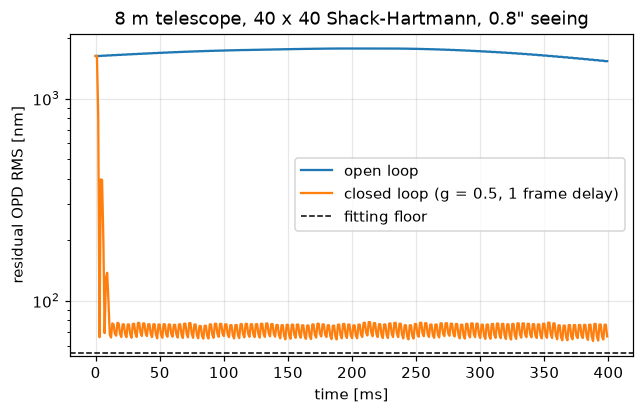

In [5]:
start = time.time()
history = run_closed_loop_ao(
    sheet, pupil, X, Y, influence, A,
    n_steps=N_STEPS, wind_shift_per_step=(WIND / FRAME_RATE / DELTA, 0), gain=GAIN, delay_frames=DELAY,
    n_lenslets=N_LENSLETS, min_fill=0.5, reconstructor=R, compute_strehl=False, record_every=10,
)
print(f"{N_STEPS} frames in {time.time() - start:.0f} s")

time_ms = np.arange(N_STEPS) / FRAME_RATE * 1e3
settled = time_ms >= 100
open_nm = np.median(history["rms_atmosphere"][settled]) * to_nm
closed_nm = np.median(history["rms_before"][settled]) * to_nm
print(f"Open loop {open_nm:.0f} nm -> closed loop {closed_nm:.0f} nm (median after 100 ms)")
print(f"Above the fitting floor, in quadrature: {np.sqrt(closed_nm**2 - (fit_rms * to_nm) ** 2):.0f} nm of servo lag and aliasing")

fig, ax = plt.subplots(figsize=(6.6, 3.8))
ax.semilogy(time_ms, history["rms_atmosphere"] * to_nm, label="open loop")
ax.semilogy(time_ms, history["rms_before"] * to_nm, label=f"closed loop (g = {GAIN}, {DELAY} frame delay)")
ax.axhline(fit_rms * to_nm, color="k", ls="--", lw=1, label="fitting floor")
ax.set(xlabel="time [ms]", ylabel="residual OPD RMS [nm]", title="8 m telescope, 40 x 40 Shack-Hartmann, 0.8\" seeing")
ax.legend()
fig.savefig(FIGURES / "06_rms_history.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Near-infrared images and the Maréchal check

The mirror corrects an optical path difference, so the same residual is a smaller phase at longer wavelength: $\phi_{\mathrm{sci}} = \phi_{\mathrm{WFS}}\,\lambda_{\mathrm{WFS}}/\lambda_{\mathrm{sci}}$. For each recorded frame after 100 ms the image Strehl ratio (PSF peak against the perfect PSF) is compared with the exponential (extended Maréchal) approximation $S \approx e^{-\sigma^2}$ ([Mahajan 1983](https://doi.org/10.1364/JOSA.73.000860)). These are instantaneous peak ratios; their median differs from the peak ratio of a time-averaged PSF.

In [6]:
BANDS = {"J": 1.25e-6, "H": 1.65e-6, "K": 2.20e-6}
PAD = 4
ideal = compute_psf_from_phase(np.zeros_like(X), pupil, pad_factor=PAD)
frames = history["residual_frames"]
maps = history["residual_maps"][frames >= 100]

print("band   Marechal exp(-sigma^2)   image Strehl   open-loop Strehl")
for band, wavelength in BANDS.items():
    ratio = WFS_WAVELENGTH / wavelength
    marechal = [np.exp(-np.nanvar(m[pupil] * ratio)) for m in maps]
    image = [compute_psf_from_phase(m * ratio, pupil, pad_factor=PAD).max() / ideal.max() for m in maps]
    atmosphere = frozen_flow_shift(sheet, int(frames[-1] * WIND / FRAME_RATE / DELTA), 0, mask=pupil)
    open_strehl = compute_psf_from_phase(atmosphere * ratio, pupil, pad_factor=PAD).max() / ideal.max()
    print(f"  {band}    {np.median(marechal):20.3f} {np.median(image):14.3f} {open_strehl:18.4f}")

band   Marechal exp(-sigma^2)   image Strehl   open-loop Strehl


  J                   0.879          0.882             0.0193


  H                   0.929          0.930             0.0324


  K                   0.959          0.960             0.0756


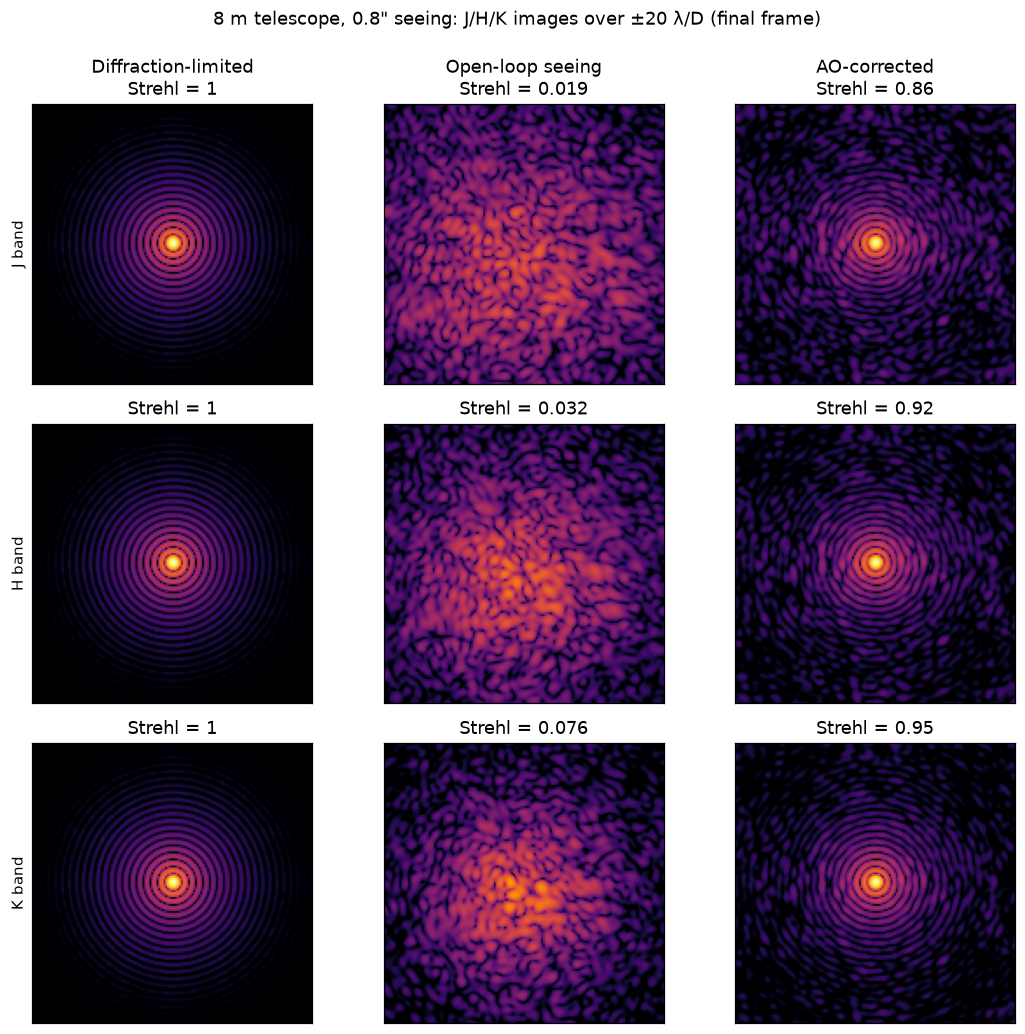

In [7]:
final = history["residual_maps"][-1]
atmosphere = frozen_flow_shift(sheet, int(frames[-1] * WIND / FRAME_RATE / DELTA), 0, mask=pupil)
c = ideal.shape[0] // 2
h = 20 * PAD                                  # +/- 20 lambda/D
titles = ["Diffraction-limited", "Open-loop seeing", "AO-corrected"]
fig, axes = plt.subplots(3, 3, figsize=(10, 9.4))
for row, (band, wavelength) in enumerate(BANDS.items()):
    ratio = WFS_WAVELENGTH / wavelength
    images = [ideal, compute_psf_from_phase(atmosphere * ratio, pupil, pad_factor=PAD), compute_psf_from_phase(final * ratio, pupil, pad_factor=PAD)]
    for col, image in enumerate(images):
        ax = axes[row, col]
        ax.imshow(np.maximum(image[c - h:c + h, c - h:c + h], ideal.max() * 1e-5), origin="lower", cmap="inferno",
                  norm=plt.matplotlib.colors.LogNorm(vmin=ideal.max() * 1e-5, vmax=ideal.max()))
        ax.set_title(f"{titles[col]}\nStrehl = {image.max() / ideal.max():.2g}" if row == 0 else f"Strehl = {image.max() / ideal.max():.2g}")
        ax.set_ylabel(f"{band} band" if col == 0 else "")
        ax.set_xticks([])
        ax.set_yticks([])
        ax.grid(False)
fig.suptitle(f"8 m telescope, 0.8\" seeing: J/H/K images over ±20 λ/D (final frame)", y=0.995)
plt.tight_layout()
fig.savefig(FIGURES / "06_jhk_psf.png", dpi=150, bbox_inches="tight")
plt.show()

## Summary

- With 1517 actuators (guard ring included) and 1260 sub-apertures, the loop takes 1.74 µm of open-loop wavefront error, mostly tip/tilt, down to 72 nm.
- The fitting floor is 55 nm ($\kappa = 0.22$, as in notebook 05). The remaining 47 nm, in quadrature, is servo lag and aliasing: one additional frame of measurement delay at a simulated 1 ms cadence against a Greenwood frequency of 21 Hz.
- The image Strehl ratios are J 0.88, H 0.93 and K 0.96, matching the Maréchal estimate to within 0.003; in open loop they are only 0.02–0.08.
- Not modelled here: detector noise (notebooks 04 and 05), several turbulent layers and anisoplanatism, non-common-path aberrations, and a measured mirror or detector calibration.